# Credit Card Fraud 2023: Exploratory Data Analysis

Load the local dataset, inspect the first rows and missing values, prepare fields for analysis, and summarize and plot the feature distributions.

In [1]:
from pathlib import Path

import pandas as pd

data_path = Path("datasets") / "creditcard_2023.csv"
df = pd.read_csv(data_path)

print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

print("\nColumn data types:")
display(df.dtypes.rename("dtype").to_frame())

Dataset shape: 568,630 rows × 31 columns


,id,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-0.260648,-0.469648,2.496266,-0.083724,0.129681,0.732898,0.519014,-0.130006,0.727159,...,-0.110552,0.217606,-0.134794,0.165959,0.126280,-0.434824,-0.081230,-0.151045,17982.10,0
1,1,0.985100,-0.356045,0.558056,-0.429654,0.277140,0.428605,0.406466,-0.133118,0.347452,...,-0.194936,-0.605761,0.079469,-0.577395,0.190090,0.296503,-0.248052,-0.064512,6531.37,0
2,2,-0.260272,-0.949385,1.728538,-0.457986,0.074062,1.419481,0.743511,-0.095576,-0.261297,...,-0.005020,0.702906,0.945045,-1.154666,-0.605564,-0.312895,-0.300258,-0.244718,2513.54,0
3,3,-0.152152,-0.508959,1.746840,-1.090178,0.249486,1.143312,0.518269,-0.065130,-0.205698,...,-0.146927,-0.038212,-0.214048,-1.893131,1.003963,-0.515950,-0.165316,0.048424,5384.44,0
4,4,-0.206820,-0.165280,1.527053,-0.448293,0.106125,0.530549,0.658849,-0.212660,1.049921,...,-0.106984,0.729727,-0.161666,0.312561,-0.414116,1.071126,0.023712,0.419117,14278.97,0



Column data types:


,dtype
id,int64
V1,float64
V2,float64
V3,float64
V4,float64
V5,float64
V6,float64
V7,float64
V8,float64
V9,float64


## Missing values and data preparation

Keep the raw data unchanged. Treat `id` as a record identifier rather than a feature, and `Class` as the binary target rather than a continuous measurement. The V1–V28 fields are already standardized, so they are not scaled again.

In [2]:
missing_summary = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
})
print(f"Total missing values: {int(df.isna().sum().sum()):,}")
display(missing_summary)

# Exclude the row identifier from analysis and mark the binary label as categorical.
df_prepared = df.drop(columns="id").copy()
df_prepared["Class"] = df_prepared["Class"].astype("category")

print(f"Rows retained: {len(df_prepared):,} of {len(df):,}")
print("Class counts:")
display(df_prepared["Class"].value_counts().sort_index().rename("transactions").to_frame())
print("Prepared data types:")
display(df_prepared.dtypes.rename("prepared_dtype").to_frame())

Total missing values: 0


,missing_values,missing_percent
id,0,0.0
V1,0,0.0
V2,0,0.0
V3,0,0.0
V4,0,0.0
V5,0,0.0
V6,0,0.0
V7,0,0.0
V8,0,0.0
V9,0,0.0


Rows retained: 568,630 of 568,630
Class counts:


,transactions
Class,
0,284315
1,284315


Prepared data types:


,prepared_dtype
V1,float64
V2,float64
V3,float64
V4,float64
V5,float64
V6,float64
V7,float64
V8,float64
V9,float64
V10,float64


## Mean, median, and standard deviation

Statistics cover V1–V28 and `Amount`. The record ID is excluded, and class balance is shown separately above because `Class` is a label.

In [3]:
feature_columns = [column for column in df_prepared.columns if column.startswith("V")] + ["Amount"]
statistics = pd.DataFrame({
    "mean": df_prepared[feature_columns].mean(),
    "median": df_prepared[feature_columns].median(),
    "std_deviation": df_prepared[feature_columns].std(),
}).round(3)
display(statistics)

,mean,median,std_deviation
V1,-0.000,-0.094,1.000
V2,-0.000,-0.136,1.000
V3,0.000,0.000,1.000
V4,0.000,-0.074,1.000
V5,0.000,0.081,1.000
V6,0.000,0.079,1.000
V7,0.000,0.233,1.000
V8,0.000,-0.115,1.000
V9,0.000,0.093,1.000
V10,0.000,0.263,1.000


## Feature distributions

Histograms show all 28 standardized features and transaction amount. A separate bar chart shows the two class counts.

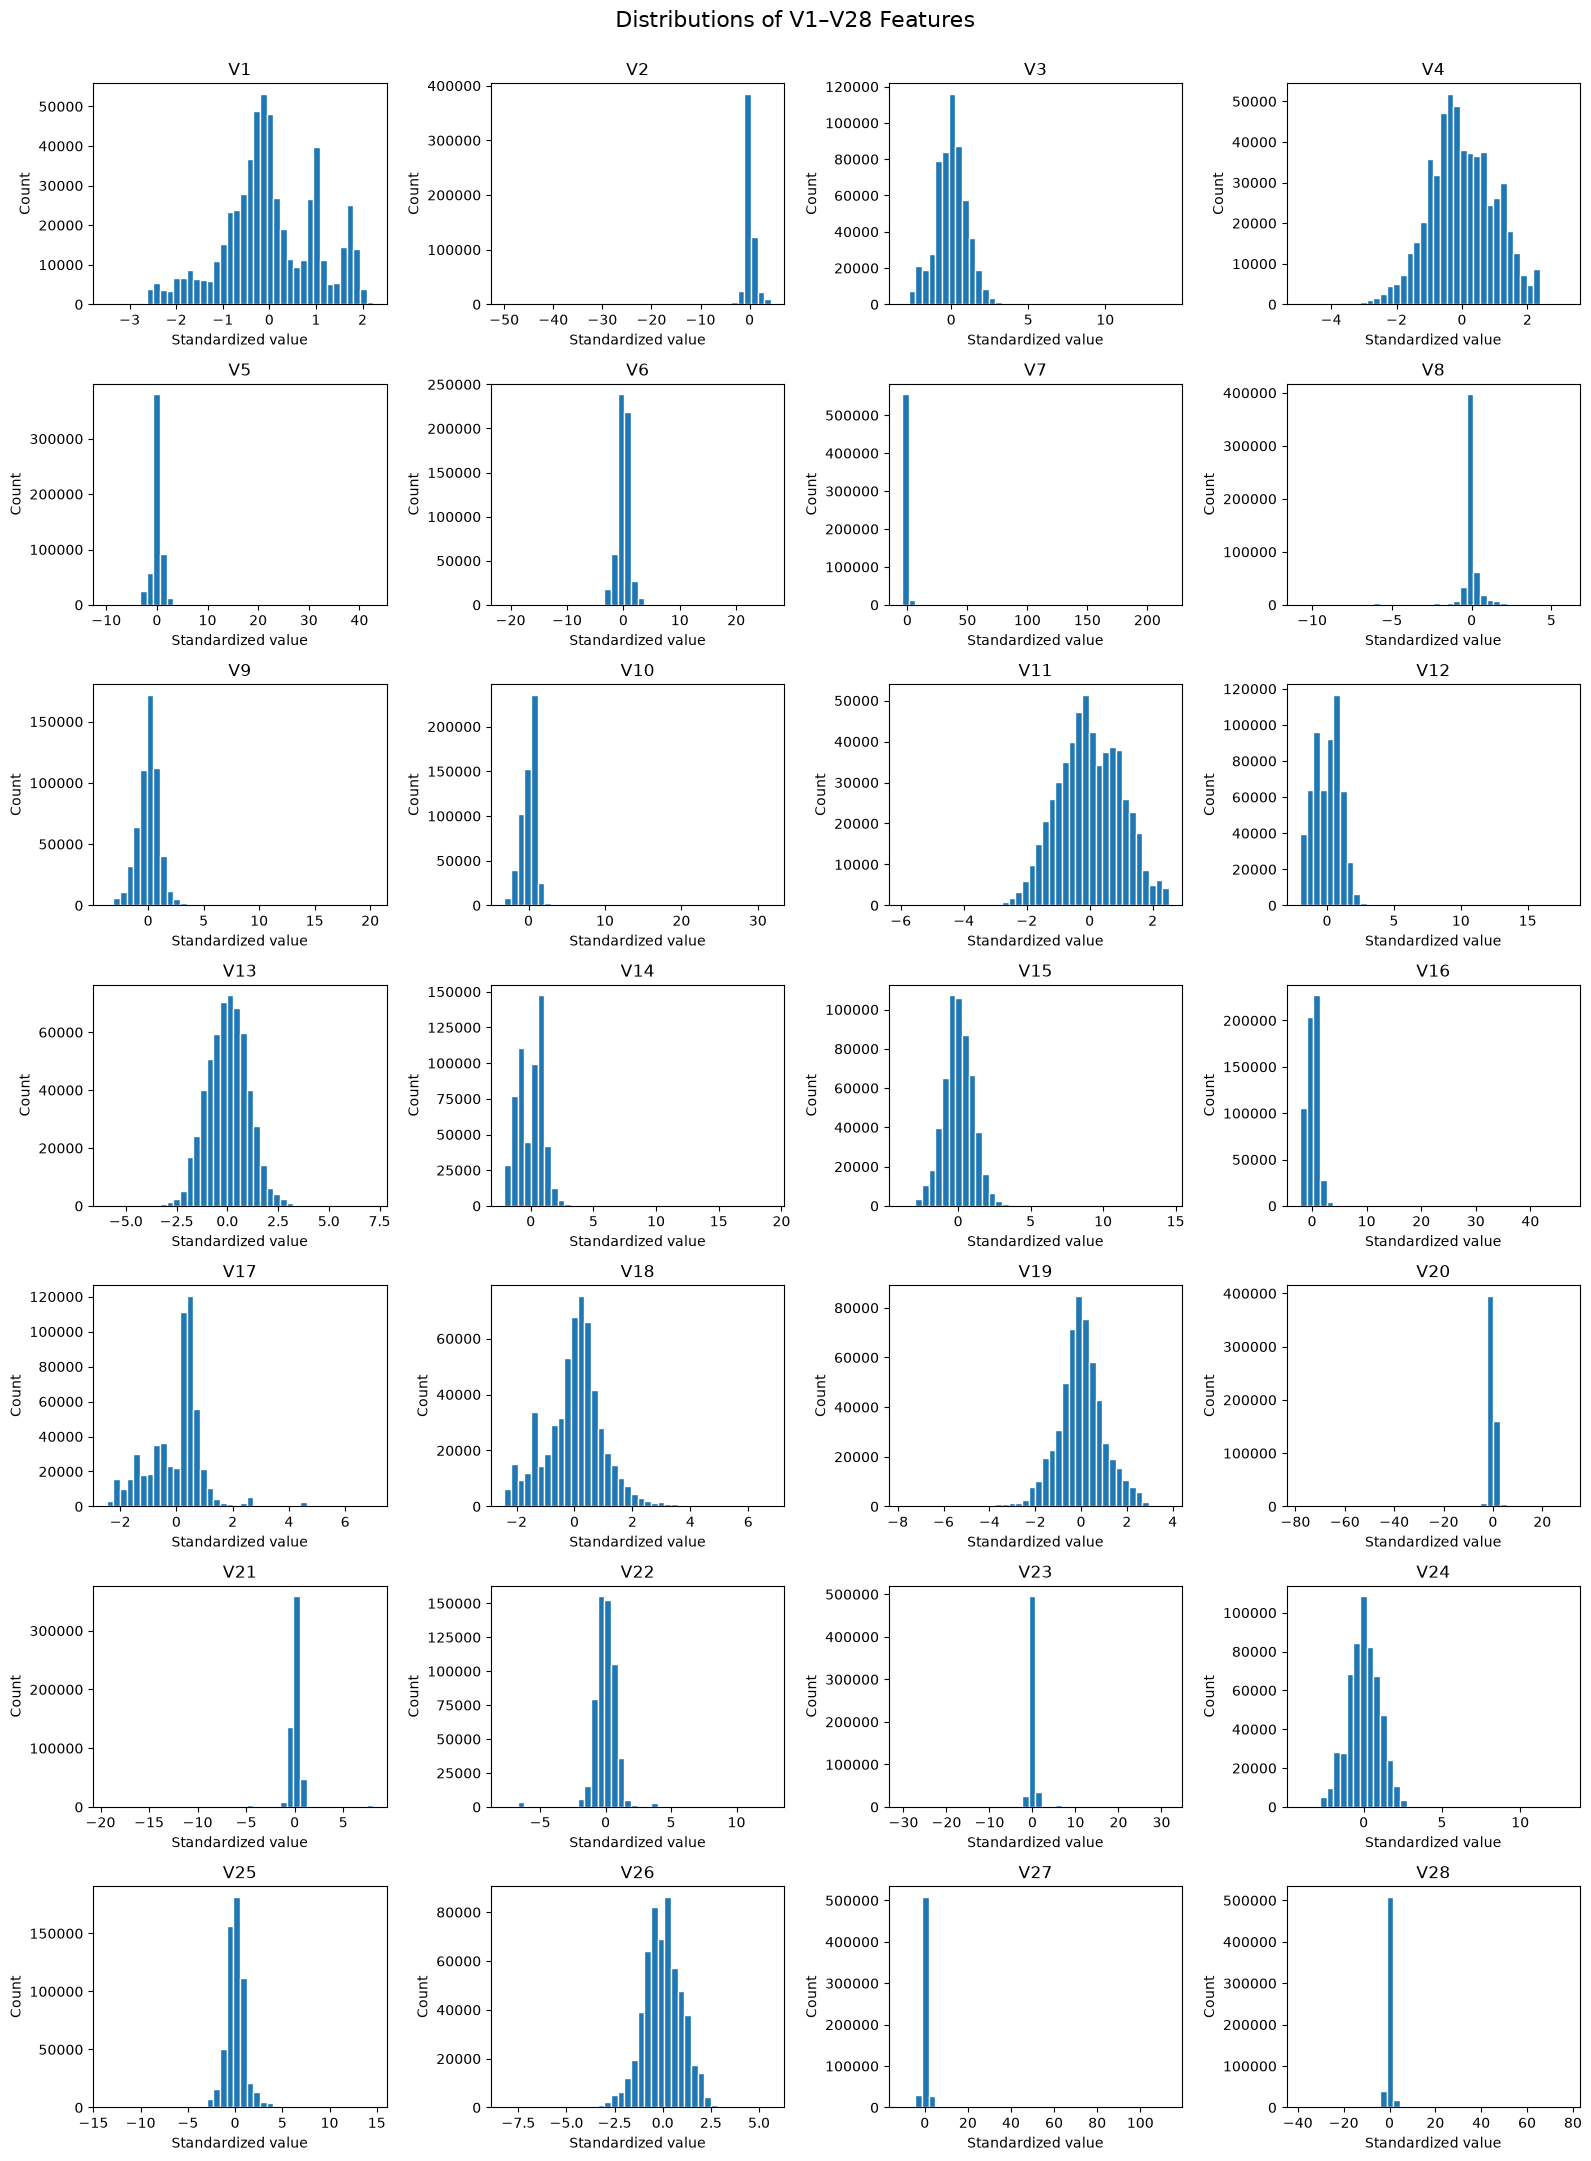

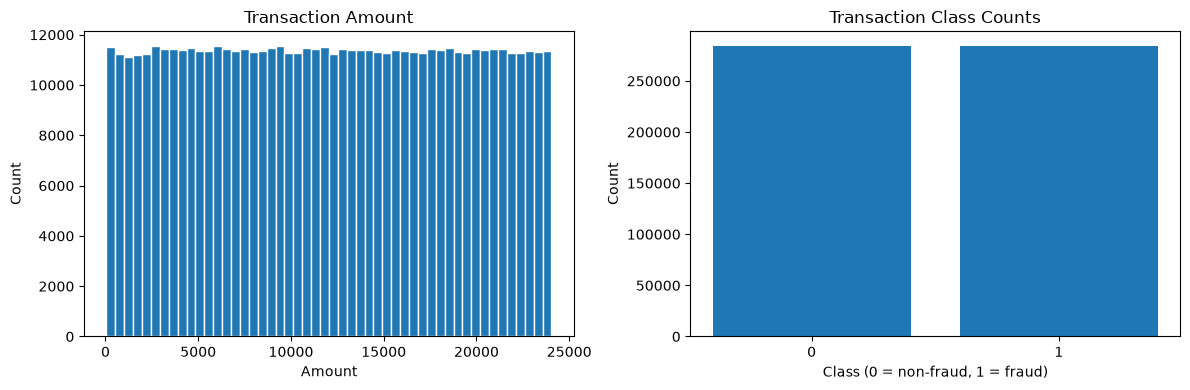

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(7, 4, figsize=(16, 22))
for column, ax in zip([column for column in df_prepared.columns if column.startswith("V")], axes.flat):
    ax.hist(df_prepared[column], bins=40, edgecolor="white")
    ax.set_title(column)
    ax.set_xlabel("Standardized value")
    ax.set_ylabel("Count")
fig.suptitle("Distributions of V1–V28 Features", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df_prepared["Amount"], bins=50, edgecolor="white")
axes[0].set_title("Transaction Amount")
axes[0].set_xlabel("Amount")
axes[0].set_ylabel("Count")

class_counts = df_prepared["Class"].value_counts().sort_index()
axes[1].bar(class_counts.index.astype(str), class_counts.values)
axes[1].set_title("Transaction Class Counts")
axes[1].set_xlabel("Class (0 = non-fraud, 1 = fraud)")
axes[1].set_ylabel("Count")
fig.tight_layout()
plt.show()